# EDA — Synthetic Vehicle Insurance Fraud

This notebook is **read-only**: it only reads the Parquet files that generated by `notebooks/vehicle_insurance_fraud_synth.ipynb` and does not write, modify, or regenerate anything. The dataset generator and export live in `notebooks/vehicle_insurance_fraud_synth.ipynb`.

**Coverage:** table profiles, relational integrity, label noise, MNAR missingness, deliberate dirty data, univariate signal, workshop/ring patterns, the leakage trap, 2025 drift, fairness, split sanity checks, and feature correlation.

**Requirements:** `pandas`, `numpy`, `pyarrow`, `matplotlib`, `seaborn`, and `scikit-learn` (used only to compute leakage AUC).

> Every number here comes from synthetic data. Always label each quoted metric as **"synthetic data"**.

## 1. Setup and data-folder resolution

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {0: "#4C72B0", 1: "#C44E52"}

In [3]:
def find_data_dir() -> Path:
    # Locate the data/ folder from either data/notebooks or the repo root.
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if (candidate / "claims.parquet").exists() and (candidate / "manifest.json").exists():
            return candidate
        nested = candidate / "data"
        if (nested / "claims.parquet").exists() and (nested / "manifest.json").exists():
            return nested
    raise FileNotFoundError(
        "Could not find the data/ folder. Run the notebook from data/notebooks or the project root."
    )


DATA_DIR = find_data_dir()
TABLE_NAMES = ["customers", "policies", "claims", "workshops", "claims_truth", "claims_features"]

customers = pd.read_parquet(DATA_DIR / "customers.parquet")
policies = pd.read_parquet(DATA_DIR / "policies.parquet")
claims = pd.read_parquet(DATA_DIR / "claims.parquet")
workshops = pd.read_parquet(DATA_DIR / "workshops.parquet")
truth = pd.read_parquet(DATA_DIR / "claims_truth.parquet")
features = pd.read_parquet(DATA_DIR / "claims_features.parquet")

# Truth is for diagnostics only. Its columns must never enter a model.
features = features.merge(truth, on="claim_id", how="left", validate="one_to_one")
manifest = json.loads((DATA_DIR / "manifest.json").read_text(encoding="utf-8"))

print(f"Data directory : {DATA_DIR}")
print(f"Python         : {__import__('platform').python_version()}")
print(f"pandas         : {pd.__version__} | numpy {np.__version__}")
print(f"Seed           : {manifest.get('seed')}")
print()
print(f"customers        {customers.shape}")
print(f"policies         {policies.shape}")
print(f"claims (raw)     {claims.shape}")
print(f"workshops        {workshops.shape}")
print(f"claims_truth     {truth.shape}")
print(f"claims_features  {features.shape}")

Data directory : /content
Python         : 3.13.18
pandas         : 2.2.3 | numpy 2.1.3
Seed           : 20261028

customers        (80000, 7)
policies         (100000, 12)
claims (raw)     (150300, 20)
workshops        (304, 6)
claims_truth     (150000, 5)
claims_features  (150000, 52)


## 2. File inventory and schema

`claims_features.parquet` is the analysis table built from `claims` + `policies` + `customers`, with normalized categories and derived features. It **still contains the leakage columns**; see section 9. When loaded, the notebook merges `claims_truth.parquet` for diagnostics, so the displayed shape gains four truth columns (48 stored columns + 4 diagnostic columns).

In [4]:
inventory = pd.DataFrame(
    [
        {
            "file": path.name,
            "size_mb": round(path.stat().st_size / 1024**2, 2),
            "rows": int(pd.read_parquet(path, columns=[]).shape[0]),
        }
        for path in sorted(DATA_DIR.glob("*.parquet"))
    ]
)
display(inventory)

row_counts = pd.Series(
    {
        "customers": len(customers),
        "policies": len(policies),
        "claims raw": len(claims),
        "claims unique": claims["claim_id"].nunique(),
        "workshops": len(workshops),
        "truth": len(truth),
        "features": len(features),
    },
    name="rows",
).to_frame()
display(row_counts)
print(json.dumps(manifest, indent=2))

,file,size_mb,rows
0,claims.parquet,4.5700,0
1,claims_features.parquet,9.6700,0
2,claims_truth.parquet,2.3000,0
3,customers.parquet,0.9100,0
4,policies.parquet,2.2600,0
5,workshops.parquet,0.0100,0


,rows
customers,80000
policies,100000
claims raw,150300
claims unique,150000
workshops,304
truth,150000
features,150000


{
  "generated_at_utc": "2026-10-28T13:17:47.804422+00:00",
  "seed": 20261028,
  "python": "3.13.18",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "row_counts": {
    "customers": 80000,
    "policies": 100000,
    "claims_including_duplicates": 150300,
    "claims_unique": 150000,
    "workshops": 304
  },
  "observed_fraud_rate": 0.03072521623419827,
  "latent_true_fraud_rate": 0.03610666666666667,
  "calibrated_intercept": -5.348511242603301,
  "parquet_bytes": {
    "claims.parquet": 4791476,
    "claims_features.parquet": 10142296,
    "claims_truth.parquet": 2411102,
    "customers.parquet": 950704,
    "policies.parquet": 2373614,
    "workshops.parquet": 12277
  },
  "feature_rows": 150000,
  "feature_columns": 48,
  "features_exclude_truth": true
}


In [5]:
def profile_table(name: str, frame: pd.DataFrame) -> None:
    profile = pd.DataFrame(
        {
            "dtype": frame.dtypes.astype(str),
            "non_null": frame.notna().sum(),
            "null_pct": (frame.isna().mean() * 100).round(2),
            "n_unique": frame.nunique(dropna=True),
        }
    )
    profile.index.name = "column"
    print(f"\n{name}: {len(frame):,} rows x {frame.shape[1]} columns")
    display(profile)


for name, frame in [
    ("customers", customers),
    ("policies", policies),
    ("claims", claims),
    ("workshops", workshops),
    ("claims_truth", truth),
    ("claims_features", features),
]:
    profile_table(name, frame)


customers: 80,000 rows x 7 columns


,dtype,non_null,null_pct,n_unique
column,,,,
customer_id,object,80000,0.0000,80000
age,int64,80000,0.0000,58
occupation_group,object,80000,0.0000,16
province,object,80000,0.0000,12
customer_since,datetime64[ns],80000,0.0000,6030
customer_tenure_months,int64,80000,0.0000,205
n_policies_total,int8,80000,0.0000,2



policies: 100,000 rows x 12 columns


,dtype,non_null,null_pct,n_unique
column,,,,
policy_id,object,100000,0.0000,100000
customer_id,object,100000,0.0000,80000
policy_start_date,datetime64[ns],100000,0.0000,1734
policy_end_date,datetime64[ns],100000,0.0000,1734
coverage_type,object,100000,0.0000,5
vehicle_type,object,100000,0.0000,4
vehicle_age_years,int64,100000,0.0000,26
vehicle_value,float64,100000,0.0000,10666
sum_insured,float64,100000,0.0000,10743



claims: 150,300 rows x 20 columns


...

,dtype,non_null,null_pct,n_unique
column,,,,
workshop_id,object,304,0.0000,304
workshop_name,object,304,0.0000,304
province,object,304,0.0000,12
city,object,304,0.0000,38
is_authorized_workshop,int64,304,0.0000,2
opened_date,datetime64[ns],304,0.0000,291



claims_truth: 150,000 rows x 5 columns


,dtype,non_null,null_pct,n_unique
column,,,,
claim_id,object,150000,0.0000,150000
true_fraud,int64,150000,0.0000,2
detected,int64,150000,0.0000,2
fraud_probability,float64,150000,0.0000,150000
ring_era,object,150000,0.0000,3



claims_features: 150,000 rows x 52 columns


,dtype,non_null,null_pct,n_unique
column,,,,
claim_id,object,150000,0.0000,150000
policy_id,object,150000,0.0000,77604
customer_id,object,150000,0.0000,65434
incident_date,datetime64[ns],150000,0.0000,1822
report_date,datetime64[ns],150000,0.0000,1963
incident_type,object,150000,0.0000,10
incident_hour,float64,141876,5.4200,24
incident_province,object,150000,0.0000,12
claim_amount,float64,150000,0.0000,11901


## 3. Relational integrity

Checks: primary-key uniqueness, intentional duplicates, orphan foreign keys, truth coverage, and date ranges.

In [6]:
key_checks = [
    ("customers", customers, "customer_id"),
    ("policies", policies, "policy_id"),
    ("claims", claims, "claim_id"),
    ("workshops", workshops, "workshop_id"),
    ("claims_truth", truth, "claim_id"),
    ("claims_features", features, "claim_id"),
]

integrity = []
for name, frame, key in key_checks:
    duplicated = int(frame.duplicated(key).sum())
    integrity.append(
        {
            "table": name,
            "key": key,
            "rows": len(frame),
            "unique_keys": frame[key].nunique(),
            "duplicate_key_rows": duplicated,
            "key_unique": duplicated == 0,
        }
    )
display(pd.DataFrame(integrity))

orphans = pd.DataFrame(
    {
        "relation": ["claims.policy_id -> policies", "claims.customer_id -> customers", "claims.workshop_id -> workshops"],
        "orphan_rows": [
            int((~claims["policy_id"].isin(policies["policy_id"])).sum()),
            int((~claims["customer_id"].isin(customers["customer_id"])).sum()),
            int((~claims["workshop_id"].isin(workshops["workshop_id"])).sum()),
        ],
    }
)
display(orphans)

print("Duplicate claim examples (same claim_id, identical payload):")
display(
    claims[claims.duplicated("claim_id", keep=False)]
    .sort_values("claim_id")
    .head(6)
)

coverage = pd.DataFrame(
    {
        "check": [
            "unique claim_id covered by truth",
            "unique claim_id covered by features",
            "claims rows with truth columns missing",
        ],
        "value": [
            claims["claim_id"].nunique() - truth["claim_id"].nunique(),
            claims["claim_id"].nunique() - features["claim_id"].nunique(),
            int(features["true_fraud"].isna().sum()),
        ],
    }
)
display(coverage)

date_ranges = pd.DataFrame(
    {
        "table": ["policies", "claims", "features"],
        "min_date": [
            policies["policy_start_date"].min(),
            claims["incident_date"].min(),
            features["incident_date"].min(),
        ],
        "max_date": [
            policies["policy_end_date"].max(),
            claims["incident_date"].max(),
            features["incident_date"].max(),
        ],
    }
)
display(date_ranges)

,table,key,rows,unique_keys,duplicate_key_rows,key_unique
0,customers,customer_id,80000,80000,0,True
1,policies,policy_id,100000,100000,0,True
2,claims,claim_id,150300,150000,300,False
3,workshops,workshop_id,304,304,0,True
4,claims_truth,claim_id,150000,150000,0,True
5,claims_features,claim_id,150000,150000,0,True


,relation,orphan_rows
0,claims.policy_id -> policies,0
1,claims.customer_id -> customers,0
2,claims.workshop_id -> workshops,0


Duplicate claim examples (same claim_id, identical payload):


column,claim_id,policy_id,customer_id,incident_date,report_date,incident_type,incident_hour,incident_province,claim_amount,police_report_filed,witness_count,workshop_id,is_authorized_workshop,prior_claims_12m,prior_claims_total,is_fraud,claim_status,payout_amount,siu_investigation_flag,days_to_settlement
17083,CLM0000129,P0002617,C002076,2025-07-03,2025-07-05,collision,6.0000,Jawa Timur,"6,250,000.0000",1.0000,1.0000,W0114,0,2,2,0,approved,"4,250,000.0000",0,44
109841,CLM0000129,P0002617,C002076,2025-07-03,2025-07-05,collision,6.0000,Jawa Timur,"6,250,000.0000",1.0000,1.0000,W0114,0,2,2,0,approved,"4,250,000.0000",0,44
4540,CLM0001015,P0079008,C063223,2025-07-12,2025-07-21,fire,13.0000,Sumatera Utara,"52,750,000.0000",1.0000,2.0000,W0209,0,1,1,0,approved,"50,172,000.0000",0,13
18265,CLM0001015,P0079008,C063223,2025-07-12,2025-07-21,fire,13.0000,Sumatera Utara,"52,750,000.0000",1.0000,2.0000,W0209,0,1,1,0,approved,"50,172,000.0000",0,13
107962,CLM0001763,P0074729,C059804,2022-02-09,2022-02-10,collision,21.0000,Jawa Barat,"550,000.0000",NaN,1.0000,W0072,1,0,0,0,approved,"428,000.0000",0,15
37117,CLM0001763,P0074729,C059804,2022-02-09,2022-02-10,collision,21.0000,Jawa Barat,"550,000.0000",NaN,1.0000,W0072,1,0,0,0,approved,"428,000.0000",0,15


,check,value
0,unique claim_id covered by truth,0
1,unique claim_id covered by features,0
2,claims rows with truth columns missing,0


,table,min_date,max_date
0,policies,2021-01-01,2026-09-30
1,claims,2021-01-05,2025-12-31
2,features,2021-01-05,2025-12-31


## 4. Target and label noise

`is_fraud` is the **observed** label. `true_fraud` in `claims_truth.parquet` is the latent truth used only for diagnostics. The difference is label noise: 15% of fraudulent claims are never detected and are labelled 0.

In [7]:
target = claims["is_fraud"].value_counts(dropna=False).rename("rows").to_frame()
target["share_pct"] = (target["rows"] / len(claims) * 100).round(3)
display(target)

truth_summary = pd.DataFrame(
    {
        "metric": [
            "observed fraud rate (is_fraud)",
            "latent fraud rate (true_fraud)",
            "true frauds",
            "detected frauds (labelled 1)",
            "missed frauds (labelled 0)",
            "detection rate among true frauds",
        ],
        "value": [
            claims["is_fraud"].mean(),
            truth["true_fraud"].mean(),
            int(truth["true_fraud"].sum()),
            int(((truth["true_fraud"] == 1) & (truth["detected"] == 1)).sum()),
            int(((truth["true_fraud"] == 1) & (truth["detected"] == 0)).sum()),
            truth.loc[truth["true_fraud"] == 1, "detected"].mean(),
        ],
    }
)
display(truth_summary)

display(pd.crosstab(truth["true_fraud"], truth["detected"], margins=True, margins_name="total"))

,rows,share_pct
is_fraud,,
0,145682,96.9270
1,4618,3.0730


,metric,value
0,observed fraud rate (is_fraud),0.0307
1,latent fraud rate (true_fraud),0.0361
2,true frauds,"5,416.0000"
3,detected frauds (labelled 1),"4,606.0000"
4,missed frauds (labelled 0),810.0000
5,detection rate among true frauds,0.8504


detected,0,1,total
true_fraud,,,
0,144584,0,144584
1,810,4606,5416
total,145394,4606,150000


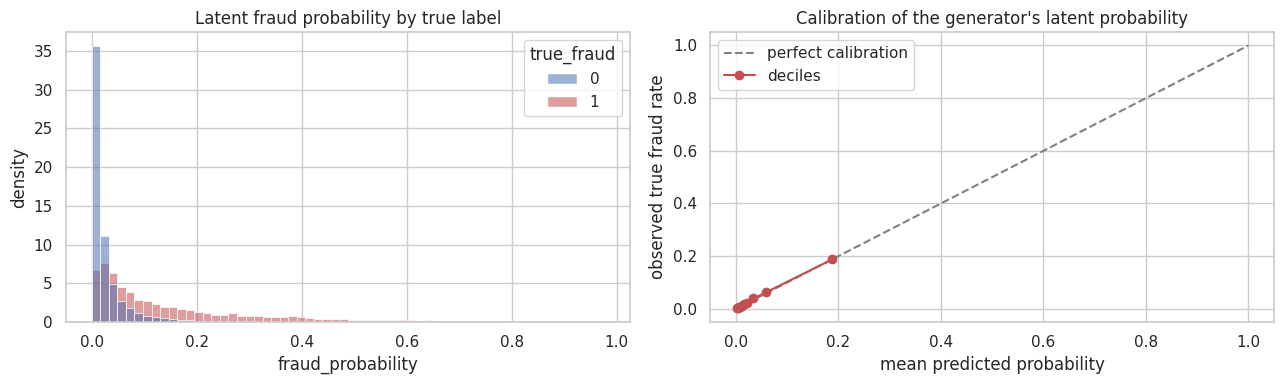

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    data=truth,
    x="fraud_probability",
    hue="true_fraud",
    bins=60,
    stat="density",
    common_norm=False,
    palette=PALETTE,
    alpha=0.55,
    ax=axes[0],
)
axes[0].set_title("Latent fraud probability by true label")
axes[0].set_xlabel("fraud_probability")
axes[0].set_ylabel("density")

calibration = (
    truth.assign(decile=pd.qcut(truth["fraud_probability"], 10, duplicates="drop"))
    .groupby("decile", observed=True)
    .agg(mean_predicted=("fraud_probability", "mean"), observed=("true_fraud", "mean"), claims=("claim_id", "size"))
)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey", label="perfect calibration")
axes[1].plot(calibration["mean_predicted"], calibration["observed"], marker="o", color="#C44E52", label="deciles")
axes[1].set_title("Calibration of the generator's latent probability")
axes[1].set_xlabel("mean predicted probability")
axes[1].set_ylabel("observed true fraud rate")
axes[1].legend()

plt.tight_layout()
plt.show()

## 5. Missingness is MNAR

Missing values are not random: `witness_count`, `police_report_filed`, and `incident_hour` are more likely to be missing for fraudulent claims. Naive median/mode imputation will blur this signal; consider per-column missing indicators.

In [9]:
missing_cols = ["incident_hour", "witness_count", "police_report_filed"]
missing_by_label = (
    claims.groupby("is_fraud")[missing_cols]
    .apply(lambda group: group.isna().mean().mul(100))
    .T
    .rename(columns={0: "non_fraud_pct", 1: "fraud_pct"})
)
missing_by_label["gap_pp"] = (missing_by_label["fraud_pct"] - missing_by_label["non_fraud_pct"]).round(2)
missing_by_label["overall_pct"] = (claims[missing_cols].isna().mean().mul(100)).round(2)
display(missing_by_label.sort_values("gap_pp", ascending=False))

pattern = (
    claims[missing_cols]
    .isna()
    .value_counts()
    .rename("claims")
    .to_frame()
    .assign(share_pct=lambda frame: (frame["claims"] / len(claims) * 100).round(3))
)
display(pattern.head(10))

is_fraud,non_fraud_pct,fraud_pct,gap_pp,overall_pct
column,,,,
witness_count,5.0720,14.7466,9.6700,5.3700
incident_hour,5.1606,13.6206,8.4600,5.4200
police_report_filed,4.0128,12.4729,8.4600,4.2700


claims  share_pct
incident_hour witness_count police_report_filed                   
False         False         False                128874    85.7450
True          False         False                  7340     4.8840
False         True          False                  7223     4.8060
              False         True                   5674     3.7750
True          True          False                   441     0.2930
False         True          True                    382     0.2540
True          False         True                    342     0.2280
              True          True                     24     0.0160

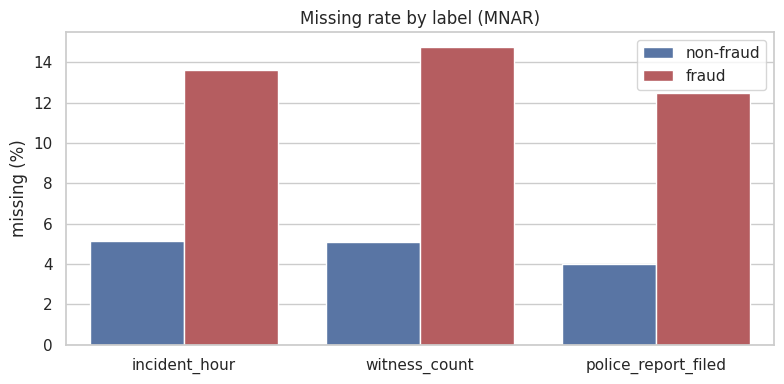

In [10]:
plot_data = missing_by_label.reset_index().rename(columns={"index": "column"})
plot_data = plot_data.melt(
    id_vars="column",
    value_vars=["non_fraud_pct", "fraud_pct"],
    var_name="group",
    value_name="missing_pct",
)
plot_data["group"] = plot_data["group"].map({"non_fraud_pct": "non-fraud", "fraud_pct": "fraud"})

plt.figure(figsize=(8, 4))
sns.barplot(data=plot_data, x="column", y="missing_pct", hue="group", palette=["#4C72B0", "#C44E52"])
plt.title("Missing rate by label (MNAR)")
plt.xlabel("")
plt.ylabel("missing (%)")
plt.legend(title="")
plt.tight_layout()
plt.show()

## 6. Deliberate dirty data

The dataset intentionally contains duplicates, category capitalization variants, negative report delays, and claim-amount outliers. This section measures how many and where.

In [11]:
def category_variants(series: pd.Series) -> tuple[int, int, int]:
    raw = series.dropna().astype(str)
    clean = raw.str.strip().str.lower()
    return raw.nunique(), clean.nunique(), int((raw != clean.str.lower()).sum())


variant_rows = []
for table_name, frame, column in [
    ("claims", claims, "incident_type"),
    ("claims", claims, "claim_status"),
    ("policies", policies, "coverage_type"),
    ("policies", policies, "sales_channel"),
    ("policies", policies, "payment_frequency"),
    ("customers", customers, "occupation_group"),
]:
    raw_n, clean_n, changed = category_variants(frame[column])
    variant_rows.append(
        {
            "table": table_name,
            "column": column,
            "raw_categories": raw_n,
            "clean_categories": clean_n,
            "rows_with_case_or_space_variant": changed,
        }
    )
display(pd.DataFrame(variant_rows))

q1, q3 = claims["claim_amount"].quantile([0.25, 0.75])
iqr = q3 - q1
quality = pd.DataFrame(
    {
        "check": [
            "duplicate claim_id rows",
            "negative report delay rows",
            "incident_hour outside 0-23",
            "claim_amount <= 0",
            "claim_amount > Q3 + 3*IQR",
            "max claim_amount",
            "median claim_amount",
        ],
        "value": [
            int(claims.duplicated("claim_id").sum()),
            int((claims["report_date"] < claims["incident_date"]).sum()),
            int(((claims["incident_hour"] < 0) | (claims["incident_hour"] > 23)).sum()),
            int((claims["claim_amount"] <= 0).sum()),
            int((claims["claim_amount"] > q3 + 3 * iqr).sum()),
            float(claims["claim_amount"].max()),
            float(claims["claim_amount"].median()),
        ],
    }
)
display(quality)

print("Top 5 claim amounts:")
display(claims.nlargest(5, "claim_amount")[["claim_id", "incident_type", "claim_amount", "is_fraud"]])

,table,column,raw_categories,clean_categories,rows_with_case_or_space_variant
0,claims,incident_type,10,5,2222
1,claims,claim_status,6,3,2302
2,policies,coverage_type,5,2,98518
3,policies,sales_channel,6,3,1488
4,policies,payment_frequency,8,4,1519
5,customers,occupation_group,16,8,1181


,check,value
0,duplicate claim_id rows,300.0000
1,negative report delay rows,451.0000
2,incident_hour outside 0-23,0.0000
3,claim_amount <= 0,0.0000
4,claim_amount > Q3 + 3*IQR,"11,806.0000"
5,max claim_amount,"11,694,167,000.0000"
6,median claim_amount,"19,600,000.0000"


Top 5 claim amounts:


column,claim_id,incident_type,claim_amount,is_fraud
95870,CLM0127451,collision,"11,694,167,000.0000",0
41206,CLM0111633,fire,"6,735,732,000.0000",0
26033,CLM0002724,flood,"6,342,867,000.0000",0
130400,CLM0002724,flood,"6,342,867,000.0000",0
27308,CLM0037745,collision,"5,825,472,000.0000",0


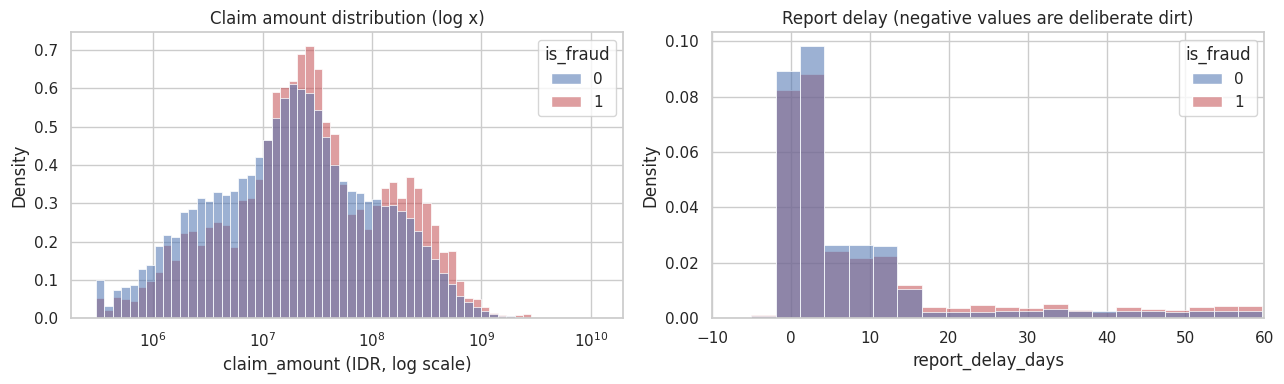

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    data=claims,
    x="claim_amount",
    hue="is_fraud",
    bins=60,
    stat="density",
    common_norm=False,
    palette=PALETTE,
    alpha=0.55,
    log_scale=(True, False),
    ax=axes[0],
)
axes[0].set_title("Claim amount distribution (log x)")
axes[0].set_xlabel("claim_amount (IDR, log scale)")

sns.histplot(
    data=features,
    x="report_delay_days",
    hue="is_fraud",
    bins=60,
    stat="density",
    common_norm=False,
    palette=PALETTE,
    alpha=0.55,
    ax=axes[1],
)
axes[1].set_xlim(-10, 60)
axes[1].set_title("Report delay (negative values are deliberate dirt)")
axes[1].set_xlabel("report_delay_days")

plt.tight_layout()
plt.show()

## 7. Univariate signal

Each flag is compared with the base rate. `lift` = fraud rate inside the flag divided by the base rate. Confidence intervals use Wilson 95%; flags with small counts must be read cautiously.

In [13]:
def wilson_ci(successes, totals, z: float = 1.96):
    successes = np.asarray(successes, dtype=float)
    totals = np.asarray(totals, dtype=float)
    safe_totals = np.where(totals > 0, totals, np.nan)
    proportion = successes / safe_totals
    denominator = 1 + z**2 / safe_totals
    centre = (proportion + z**2 / (2 * safe_totals)) / denominator
    half = z * np.sqrt(proportion * (1 - proportion) / safe_totals + z**2 / (4 * safe_totals**2)) / denominator
    return centre - half, centre + half


BASE_RATE = features["is_fraud"].mean()
print(f"Base fraud rate: {BASE_RATE:.4%}")

Base fraud rate: 3.0707%


In [14]:
flags = {
    "early_claim_60d": features["days_since_policy_start"] <= 60,
    "report_delay_gt_14d": features["report_delay_days"] > 14,
    "theft_without_police_report": (features["incident_type_clean"] == "theft") & (features["police_report_filed"] == 0),
    "claim_ratio_gt_0_8": features["claim_to_sum_insured_ratio"] > 0.8,
    "prior_claims_12m_ge_3": features["prior_claims_12m"] >= 3,
    "incident_hour_0_4": features["incident_hour"].between(0, 4),
    "non_authorized_workshop": features["is_authorized_workshop"] == 0,
    "online_and_new_customer": (features["sales_channel_clean"] == "online") & (features["customer_tenure_months"] < 12),
    "early_and_large_claim": (features["days_since_policy_start"] <= 60) & (features["claim_to_sum_insured_ratio"] > 0.8),
    "missing_police_report": features["police_report_filed"].isna(),
    "missing_witness_count": features["witness_count"].isna(),
    "missing_incident_hour": features["incident_hour"].isna(),
    "top_1pct_claim_amount": features["claim_amount"] >= features["claim_amount"].quantile(0.99),
}

rows = []
for name, mask in flags.items():
    mask = pd.Series(mask, index=features.index).fillna(False).astype(bool)
    count = int(mask.sum())
    frauds = int(features.loc[mask, "is_fraud"].sum())
    rate = frauds / count if count else np.nan
    low, high = wilson_ci(frauds, count) if count else (np.nan, np.nan)
    rows.append(
        {
            "flag": name,
            "claims": count,
            "frauds": frauds,
            "fraud_rate_pct": rate * 100,
            "lift": rate / BASE_RATE if count else np.nan,
            "ci_low_pct": low * 100,
            "ci_high_pct": high * 100,
        }
    )

flag_table = pd.DataFrame(rows).sort_values("lift", ascending=False).reset_index(drop=True)
display(flag_table)

,flag,claims,frauds,fraud_rate_pct,lift,ci_low_pct,ci_high_pct
0,early_and_large_claim,3947,541,13.7066,4.4637,12.6689,14.8149
1,theft_without_police_report,6558,626,9.5456,3.1086,8.8579,10.2807
2,missing_police_report,6406,575,8.9760,2.9231,8.3004,9.7007
3,missing_witness_count,8058,680,8.4388,2.7482,7.8515,9.0657
4,missing_incident_hour,8124,626,7.7056,2.5094,7.1454,8.3057
5,claim_ratio_gt_0_8,20649,1406,6.8090,2.2174,6.4734,7.1607
6,early_claim_60d,28218,1727,6.1202,1.9931,5.8465,6.4059
7,report_delay_gt_14d,22569,1069,4.7366,1.5425,4.4671,5.0215
8,online_and_new_customer,17917,807,4.5041,1.4668,4.2100,4.8177
9,top_1pct_claim_amount,1500,65,4.3333,1.4112,3.4143,5.4857


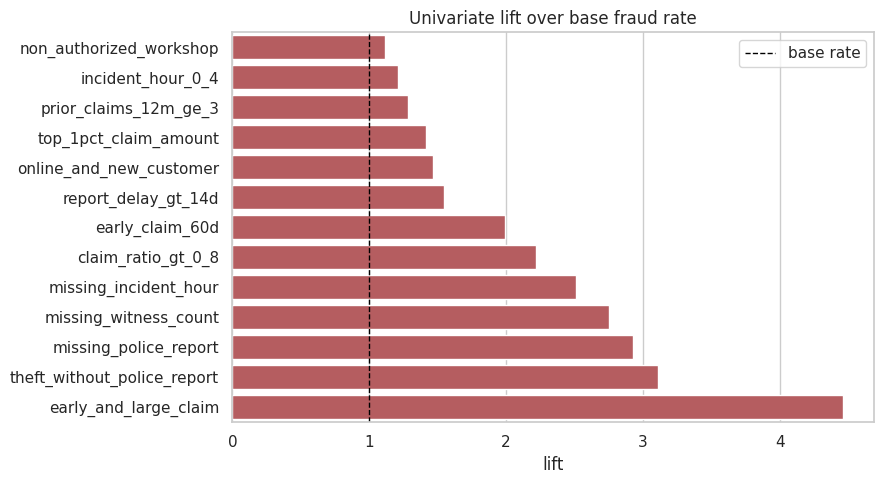

In [15]:
plot_flags = flag_table.sort_values("lift")
plt.figure(figsize=(9, 5))
sns.barplot(data=plot_flags, y="flag", x="lift", color="#C44E52")
plt.axvline(1.0, color="black", linestyle="--", linewidth=1, label="base rate")
plt.title("Univariate lift over base fraud rate")
plt.xlabel("lift")
plt.ylabel("")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Categories and workshops

Workshops are where the fraud ring is most visible. This table combines claim counts, fraud rate, and the share of claims from the ring (`ring_era != "none"`, available only in truth for diagnostics).

In [16]:
def category_rate_table(frame: pd.DataFrame, column: str, min_claims: int = 150) -> pd.DataFrame:
    grouped = (
        frame.groupby(column, dropna=False)
        .agg(claims=("claim_id", "size"), frauds=("is_fraud", "sum"), fraud_rate=("is_fraud", "mean"))
        .reset_index()
    )
    low, high = wilson_ci(grouped["frauds"], grouped["claims"])
    grouped["ci_low_pct"] = low * 100
    grouped["ci_high_pct"] = high * 100
    grouped["fraud_rate_pct"] = grouped["fraud_rate"] * 100
    grouped["lift"] = grouped["fraud_rate"] / BASE_RATE
    grouped = grouped[grouped["claims"] >= min_claims]
    return grouped.sort_values("fraud_rate", ascending=False)


category_columns = [
    "incident_type_clean",
    "sales_channel_clean",
    "coverage_type_clean",
    "payment_frequency_clean",
    "occupation_group_clean",
    "vehicle_type",
]
for column in category_columns:
    print(f"\n{column}")
    display(category_rate_table(features, column)[["claims", "frauds", "fraud_rate_pct", "lift", "ci_low_pct", "ci_high_pct", column]].rename(columns={column: "category"}))


incident_type_clean


,claims,frauds,fraud_rate_pct,lift,ci_low_pct,ci_high_pct,category
3,24417,1407,5.7624,1.8766,5.4770,6.0617,theft
1,14166,468,3.3037,1.0759,3.0218,3.6109,fire
2,15143,385,2.5424,0.8280,2.3035,2.8054,flood
0,81968,1998,2.4375,0.7938,2.3342,2.5454,collision
4,14306,348,2.4325,0.7922,2.1926,2.6981,vandalism



sales_channel_clean


,claims,frauds,fraud_rate_pct,lift,ci_low_pct,ci_high_pct,category
2,48639,1754,3.6062,1.1744,3.4441,3.7756,online
0,71066,2001,2.8157,0.9170,2.6966,2.9399,agent
1,30295,851,2.8090,0.9148,2.6289,3.0012,broker



coverage_type_clean


...

,claims,frauds,fraud_rate_pct,lift,ci_low_pct,ci_high_pct,category
1,17323,577,3.3308,1.0847,3.0738,3.6086,monthly
3,27984,874,3.1232,1.0171,2.9258,3.3335,semiannual
2,21576,673,3.1192,1.0158,2.8955,3.3596,quarterly
0,83117,2482,2.9862,0.9725,2.8726,3.1041,annual



occupation_group_clean


,claims,frauds,fraud_rate_pct,lift,ci_low_pct,ci_high_pct,category
3,5984,204,3.4091,1.1102,2.9784,3.8996,other
2,14758,483,3.2728,1.0658,2.9977,3.5722,entrepreneur
4,18056,561,3.1070,1.0118,2.8637,3.3702,professional
1,52659,1626,3.0878,1.0056,2.9434,3.2390,employee
6,30152,909,3.0147,0.9818,2.8276,3.2138,self_employed
5,7494,224,2.9891,0.9734,2.6269,3.3993,retired
0,11956,344,2.8772,0.9370,2.5924,3.1923,civil_servant
7,8941,255,2.8520,0.9288,2.5267,3.2178,student



vehicle_type


,claims,frauds,fraud_rate_pct,lift,ci_low_pct,ci_high_pct,category
1,69270,2249,3.2467,1.0573,3.1173,3.3813,motorcycle
3,7477,224,2.9959,0.9756,2.6329,3.4071,truck
2,59801,1747,2.9214,0.9514,2.7894,3.0594,private_car
0,13452,386,2.8695,0.9345,2.6005,3.1653,commercial_vehicle


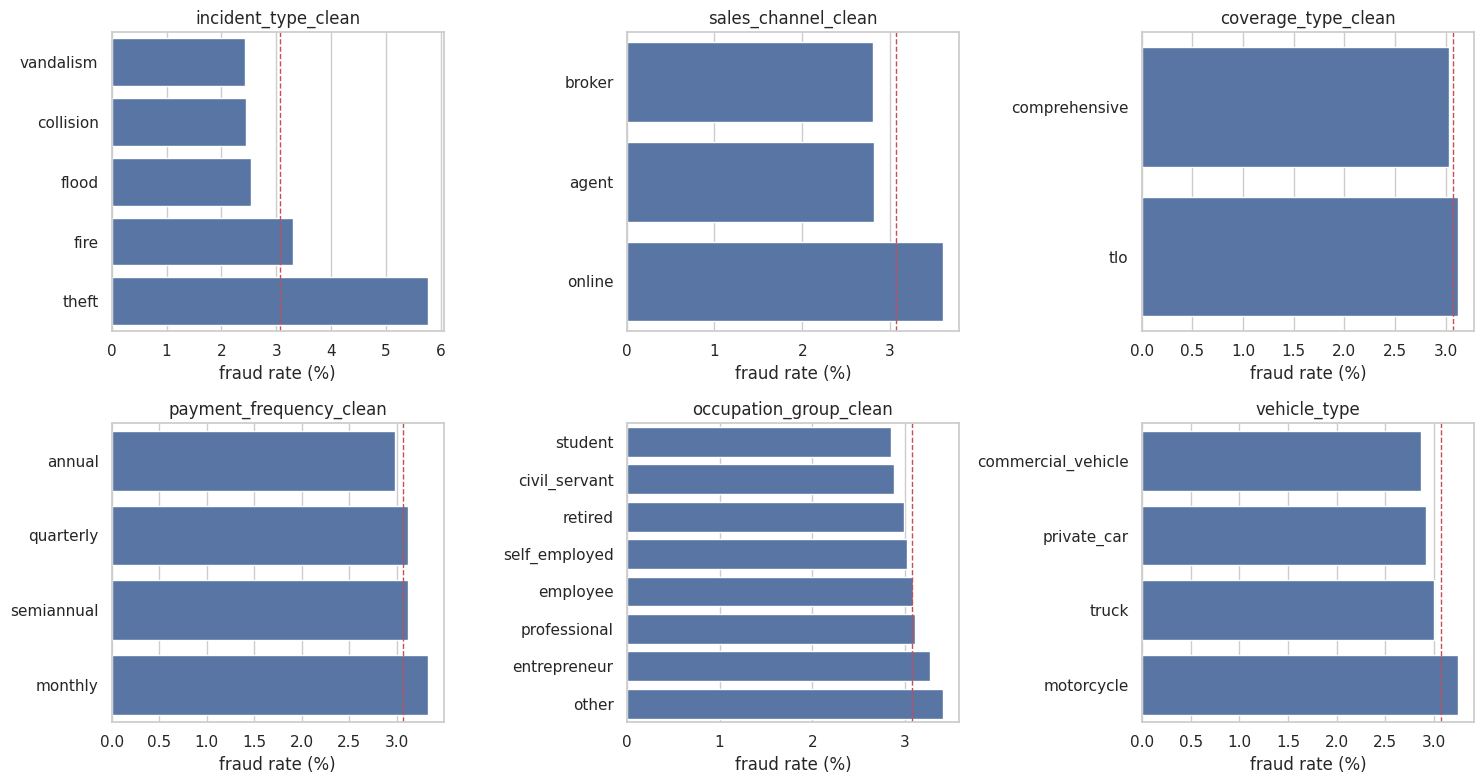

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for axis, column in zip(axes.ravel(), category_columns):
    data = category_rate_table(features, column).sort_values("fraud_rate")
    sns.barplot(data=data, y=column, x="fraud_rate_pct", color="#4C72B0", ax=axis)
    axis.axvline(BASE_RATE * 100, color="#C44E52", linestyle="--", linewidth=1)
    axis.set_title(column)
    axis.set_xlabel("fraud rate (%)")
    axis.set_ylabel("")
plt.tight_layout()
plt.show()

In [18]:
workshop_stats = (
    features.groupby("workshop_id")
    .agg(
        claims=("claim_id", "size"),
        frauds=("is_fraud", "sum"),
        fraud_rate=("is_fraud", "mean"),
        ring_share=("ring_era", lambda series: (series != "none").mean()),
    )
    .join(workshops.set_index("workshop_id")[["workshop_name", "province", "is_authorized_workshop", "opened_date"]])
)
workshop_stats["fraud_rate_pct"] = workshop_stats["fraud_rate"] * 100
workshop_stats["ring_share_pct"] = workshop_stats["ring_share"] * 100

print("Top 20 workshops by fraud rate (min 200 claims)")
display(
    workshop_stats[workshop_stats["claims"] >= 200]
    .sort_values("fraud_rate", ascending=False)
    .head(20)[["workshop_name", "province", "is_authorized_workshop", "opened_date", "claims", "frauds", "fraud_rate_pct", "ring_share_pct"]]
)

print("Authorized vs non-authorized")
display(
    features.groupby("is_authorized_workshop")
    .agg(claims=("claim_id", "size"), frauds=("is_fraud", "sum"), fraud_rate=("is_fraud", "mean"))
    .assign(fraud_rate_pct=lambda frame: frame["fraud_rate"] * 100)
)

print("Workshops opened in 2025")
display(
    workshop_stats[workshop_stats["opened_date"] >= "2025-01-01"]
    .sort_values("fraud_rate", ascending=False)[["workshop_name", "province", "is_authorized_workshop", "claims", "fraud_rate_pct", "ring_share_pct"]]
)

Top 20 workshops by fraud rate (min 200 claims)


,workshop_name,province,is_authorized_workshop,opened_date,claims,frauds,fraud_rate_pct,ring_share_pct
workshop_id,,,,,,,,
W0304,Sumber Motor Solo,Jawa Tengah,0,2025-01-01,366,61,16.6667,100.0000
W0303,Berkah Otomotif Kediri 2,Jawa Timur,0,2025-01-01,386,50,12.9534,100.0000
W0267,Cahaya Teknik Palembang,Sumatera Selatan,0,2020-09-13,814,96,11.7936,100.0000
W0283,Sumber Service Bukittinggi,Sumatera Barat,0,2019-04-17,876,103,11.7580,100.0000
W0124,Andalan Teknik Malang,Jawa Timur,1,2020-09-18,945,110,11.6402,100.0000
W0302,Sentosa Motor Cimahi,Jawa Barat,1,2025-01-01,377,39,10.3448,100.0000
W0301,Jaya Body Repair Jakarta Pusat 2,DKI Jakarta,1,2025-01-01,343,32,9.3294,100.0000
W0002,Cahaya Otomotif Jakarta Barat,DKI Jakarta,1,2017-10-21,891,77,8.6420,100.0000
W0268,Maju Auto Palembang 2,Sumatera Selatan,1,2017-02-23,821,68,8.2826,100.0000


Authorized vs non-authorized


,claims,frauds,fraud_rate,fraud_rate_pct
is_authorized_workshop,,,,
0,65029,2229,0.0343,3.4277
1,84971,2377,0.0280,2.7974


Workshops opened in 2025


,workshop_name,province,is_authorized_workshop,claims,fraud_rate_pct,ring_share_pct
workshop_id,,,,,,
W0304,Sumber Motor Solo,Jawa Tengah,0,366,16.6667,100.0000
W0303,Berkah Otomotif Kediri 2,Jawa Timur,0,386,12.9534,100.0000
W0302,Sentosa Motor Cimahi,Jawa Barat,1,377,10.3448,100.0000
W0301,Jaya Body Repair Jakarta Pusat 2,DKI Jakarta,1,343,9.3294,100.0000


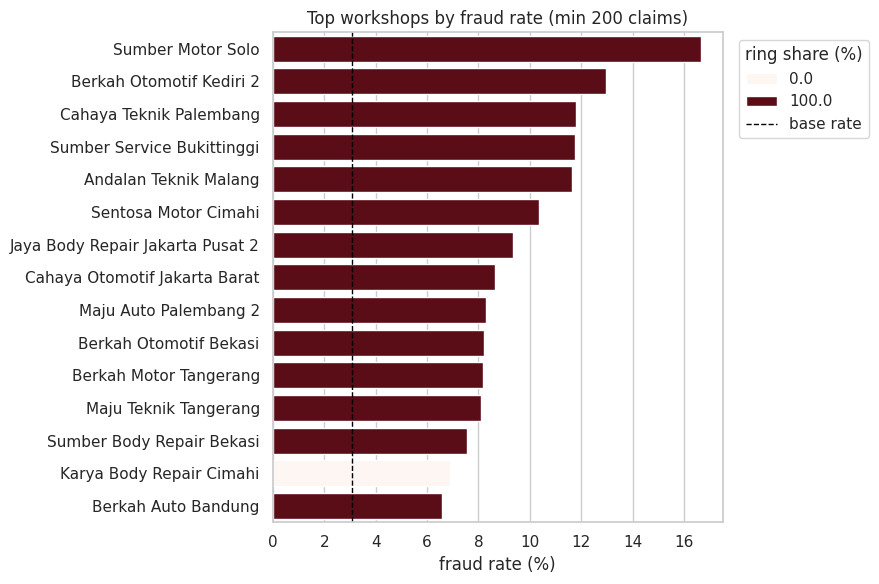

In [19]:
top_workshops = (
    workshop_stats[workshop_stats["claims"] >= 200]
    .sort_values("fraud_rate", ascending=False)
    .head(15)
    .reset_index()
)
plt.figure(figsize=(9, 6))
sns.barplot(data=top_workshops, y="workshop_name", x="fraud_rate_pct", hue="ring_share_pct", palette="Reds", dodge=False)
plt.axvline(BASE_RATE * 100, color="black", linestyle="--", linewidth=1, label="base rate")
plt.title("Top workshops by fraud rate (min 200 claims)")
plt.xlabel("fraud rate (%)")
plt.ylabel("")
plt.legend(title="ring share (%)", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 9. Leakage trap

The following four columns are only known **after** a claim has been processed. Including them in a model produces scores that look perfect but cannot be used when a new claim arrives:

| Column | Why it leaks |
|---|---|
| `claim_status` | Decision outcome; detected fraud is almost always `rejected`/`under_review`. |
| `payout_amount` | Zero for rejected fraud claims; payout size is a consequence of the decision. |
| `siu_investigation_flag` | Output of investigation triage, not an input when the claim is reported. |
| `days_to_settlement` | Time to settlement; only known after the process is complete. |

`claims_features.parquet` intentionally keeps these columns so the demonstration is reproducible. **Drop them before modeling.**

In [20]:
leakage_columns = ["claim_status_clean", "payout_amount", "siu_investigation_flag", "days_to_settlement"]

print("Fraud rate by claim_status")
display(
    features.groupby("claim_status_clean")
    .agg(claims=("claim_id", "size"), frauds=("is_fraud", "sum"), fraud_rate=("is_fraud", "mean"))
    .assign(fraud_rate_pct=lambda frame: frame["fraud_rate"] * 100)
    .sort_values("fraud_rate", ascending=False)
)

print("Fraud rate by SIU investigation flag")
display(
    features.groupby("siu_investigation_flag")
    .agg(claims=("claim_id", "size"), frauds=("is_fraud", "sum"), fraud_rate=("is_fraud", "mean"))
    .assign(fraud_rate_pct=lambda frame: frame["fraud_rate"] * 100)
)

print("Payout amount by label")
display(
    features.groupby("is_fraud")["payout_amount"]
    .agg(count="count", zero_share=lambda series: (series == 0).mean(), median="median", mean="mean")
)

print("Days to settlement by label")
display(features.groupby("is_fraud")["days_to_settlement"].agg(count="count", median="median", mean="mean"))

Fraud rate by claim_status


,claims,frauds,fraud_rate,fraud_rate_pct
claim_status_clean,,,,
rejected,12150,3460,0.2848,28.4774
under_review,7022,1146,0.1632,16.3201
approved,130828,0,0.0000,0.0000


Fraud rate by SIU investigation flag


,claims,frauds,fraud_rate,fraud_rate_pct
siu_investigation_flag,,,,
0,142813,235,0.0016,0.1646
1,7187,4371,0.6082,60.8181


Payout amount by label


,count,zero_share,median,mean
is_fraud,,,,
0,145394,0.1002,"12,504,000.0000","49,643,492.5375"
1,4606,1.0000,0.0000,0.0000


Days to settlement by label


,count,median,mean
is_fraud,,,
0,145394,26.0000,27.1745
1,4606,113.0000,112.9186


In [21]:
leakage_auc = []
for column in ["siu_investigation_flag", "payout_amount", "days_to_settlement"]:
    subset = features[[column, "is_fraud"]].dropna()
    auc = roc_auc_score(subset["is_fraud"], subset[column])
    leakage_auc.append(
        {
            "column": column,
            "non_null": len(subset),
            "auc_raw": auc,
            "separation": max(auc, 1 - auc),
        }
    )

leakage_auc = pd.DataFrame(leakage_auc).sort_values("separation", ascending=False)
display(leakage_auc)
print("AUC 0.5 = no signal; 1.0 = perfect label separation (leakage).")

,column,non_null,auc_raw,separation
2,days_to_settlement,150000,0.9907,0.9907
0,siu_investigation_flag,150000,0.9648,0.9648
1,payout_amount,150000,0.0501,0.9499


AUC 0.5 = no signal; 1.0 = perfect label separation (leakage).


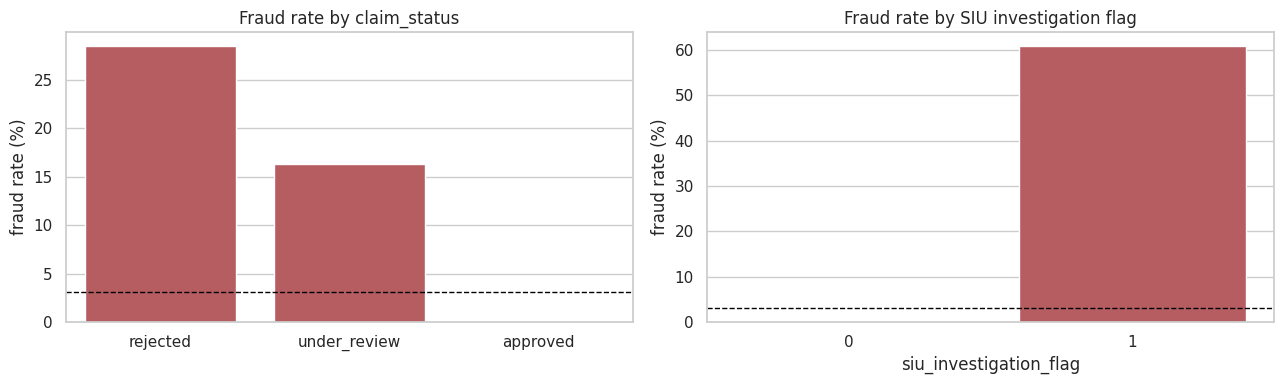

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

status_rate = (
    features.groupby("claim_status_clean")["is_fraud"].mean().mul(100).sort_values(ascending=False)
)
sns.barplot(x=status_rate.index, y=status_rate.values, color="#C44E52", ax=axes[0])
axes[0].axhline(BASE_RATE * 100, color="black", linestyle="--", linewidth=1)
axes[0].set_title("Fraud rate by claim_status")
axes[0].set_xlabel("")
axes[0].set_ylabel("fraud rate (%)")

siu_rate = features.groupby("siu_investigation_flag")["is_fraud"].mean().mul(100)
sns.barplot(x=siu_rate.index.astype(str), y=siu_rate.values, color="#C44E52", ax=axes[1])
axes[1].axhline(BASE_RATE * 100, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Fraud rate by SIU investigation flag")
axes[1].set_xlabel("siu_investigation_flag")
axes[1].set_ylabel("fraud rate (%)")

plt.tight_layout()
plt.show()

## 10. 2025 time drift

Two changes are planted in 2025: part of the legacy ring moves to four new workshops, and the online-channel effect is strengthened. This is why the split must be time-based, not random.

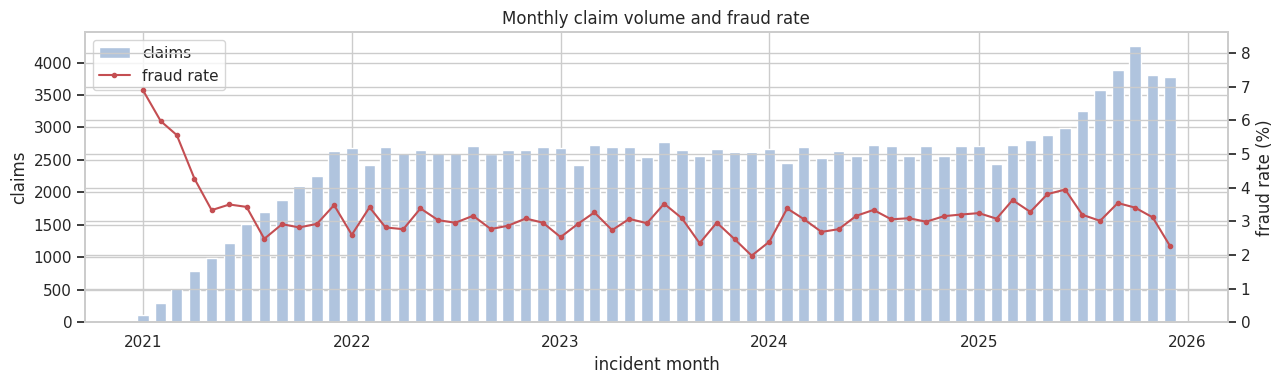

In [23]:
monthly = (
    features.set_index("incident_date")
    .resample("MS")
    .agg(claims=("claim_id", "size"), frauds=("is_fraud", "sum"))
)
monthly["fraud_rate_pct"] = monthly["frauds"] / monthly["claims"] * 100

fig, axis = plt.subplots(figsize=(13, 4))
axis.bar(monthly.index, monthly["claims"], width=20, color="#B0C4DE", label="claims")
axis.set_ylabel("claims")
axis.set_xlabel("incident month")

rate_axis = axis.twinx()
rate_axis.plot(monthly.index, monthly["fraud_rate_pct"], color="#C44E52", marker="o", markersize=3, label="fraud rate")
rate_axis.set_ylabel("fraud rate (%)")
rate_axis.set_ylim(0, max(6.0, monthly["fraud_rate_pct"].max() * 1.25))

lines = axis.get_legend_handles_labels()[0] + rate_axis.get_legend_handles_labels()[0]
labels = axis.get_legend_handles_labels()[1] + rate_axis.get_legend_handles_labels()[1]
axis.legend(lines, labels, loc="upper left")
axis.set_title("Monthly claim volume and fraud rate")
plt.tight_layout()
plt.show()

In [24]:
features["year"] = features["incident_date"].dt.year

yearly = (
    features.groupby("year")
    .agg(claims=("claim_id", "size"), frauds=("is_fraud", "sum"), fraud_rate=("is_fraud", "mean"))
    .assign(fraud_rate_pct=lambda frame: frame["fraud_rate"] * 100)
)
display(yearly)

channel_year = features.pivot_table(index="year", columns="sales_channel_clean", values="is_fraud", aggfunc="mean").mul(100)
print("Fraud rate (%) by year and sales channel")
display(channel_year)

ring_year = features.pivot_table(index="year", columns="ring_era", values="claim_id", aggfunc="count", fill_value=0)
print("Claim counts by year and ring era")
display(ring_year)

,claims,frauds,fraud_rate,fraud_rate_pct
year,,,,
2021,16038,531,0.0331,3.3109
2022,31604,943,0.0298,2.9838
2023,31687,896,0.0283,2.8277
2024,31540,954,0.0302,3.0247
2025,39131,1282,0.0328,3.2762


Fraud rate (%) by year and sales channel


sales_channel_clean,agent,broker,online
year,,,
2021,3.1396,3.3174,3.6800
2022,2.8062,2.6227,3.6179
2023,2.5892,2.7006,3.2835
2024,2.9191,2.6748,3.3565
2025,2.7783,2.9485,3.9679


Claim counts by year and ring era


ring_era,new,none,old
year,,,
2021,0,14992,1046
2022,0,29398,2206
2023,0,29632,2055
2024,0,29447,2093
2025,1472,36358,1301


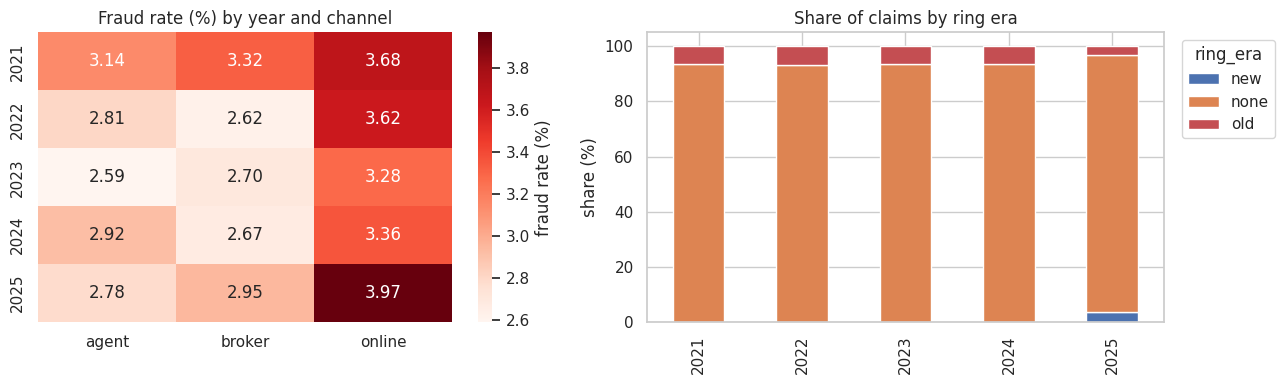

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.heatmap(channel_year, annot=True, fmt=".2f", cmap="Reds", cbar_kws={"label": "fraud rate (%)"}, ax=axes[0])
axes[0].set_title("Fraud rate (%) by year and channel")
axes[0].set_xlabel("")
axes[0].set_ylabel("")

ring_share_year = ring_year.div(ring_year.sum(axis=1), axis=0).mul(100)
ring_share_year.plot(kind="bar", stacked=True, ax=axes[1], color=["#4C72B0", "#DD8452", "#C44E52"])
axes[1].set_title("Share of claims by ring era")
axes[1].set_xlabel("")
axes[1].set_ylabel("share (%)")
axes[1].legend(title="ring_era", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

## 11. Fairness check

`age` and `province` are **not** used to generate fraud. Differences below come from noise and volume, not a causal signal. If either enters a model, the result can be read as profiling; decide explicitly and document the choice.

In [26]:
features["age_band"] = pd.cut(
    features["age"],
    bins=[17, 25, 35, 45, 55, 65, 75],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65", "66-75"],
)

age_table = (
    features.groupby("age_band", observed=True)
    .agg(claims=("claim_id", "size"), frauds=("is_fraud", "sum"), fraud_rate=("is_fraud", "mean"))
    .reset_index()
)
low, high = wilson_ci(age_table["frauds"], age_table["claims"])
age_table["ci_low_pct"] = low * 100
age_table["ci_high_pct"] = high * 100
age_table["fraud_rate_pct"] = age_table["fraud_rate"] * 100
display(age_table)

province_table = (
    features.groupby("province")
    .agg(claims=("claim_id", "size"), frauds=("is_fraud", "sum"), fraud_rate=("is_fraud", "mean"))
    .reset_index()
)
province_table = province_table[province_table["claims"] >= 500].copy()
low, high = wilson_ci(province_table["frauds"], province_table["claims"])
province_table["ci_low_pct"] = low * 100
province_table["ci_high_pct"] = high * 100
province_table["fraud_rate_pct"] = province_table["fraud_rate"] * 100
display(province_table.sort_values("fraud_rate", ascending=False))

,age_band,claims,frauds,fraud_rate,ci_low_pct,ci_high_pct,fraud_rate_pct
0,18-25,22690,682,0.0301,2.7914,3.2360,3.0057
1,26-35,40055,1238,0.0309,2.9257,3.2648,3.0908
2,36-45,47510,1451,0.0305,2.9031,3.2127,3.0541
3,46-55,28892,886,0.0307,2.8739,3.2717,3.0666
4,56-65,9256,301,0.0325,2.9095,3.6331,3.2519
5,66-75,1597,48,0.0301,2.2744,3.9624,3.0056


,province,claims,frauds,fraud_rate,ci_low_pct,ci_high_pct,fraud_rate_pct
10,Sumatera Selatan,5925,272,0.0459,4.0866,5.1537,4.5907
9,Sumatera Barat,4497,196,0.0436,3.7997,4.9952,4.3585
1,Banten,11957,410,0.0343,3.1174,3.7704,3.4290
4,Jawa Barat,25488,852,0.0334,3.1290,3.5706,3.3427
6,Jawa Timur,21261,664,0.0312,2.8976,3.3655,3.1231
5,Jawa Tengah,17730,524,0.0296,2.7162,3.2151,2.9554
11,Sumatera Utara,10364,293,0.0283,2.5250,3.1641,2.8271
3,DKI Jakarta,27113,764,0.0282,2.6274,3.0216,2.8178
7,Kalimantan Timur,4493,117,0.0260,2.1773,3.1118,2.6041
2,DI Yogyakarta,7500,191,0.0255,2.2137,2.9282,2.5467


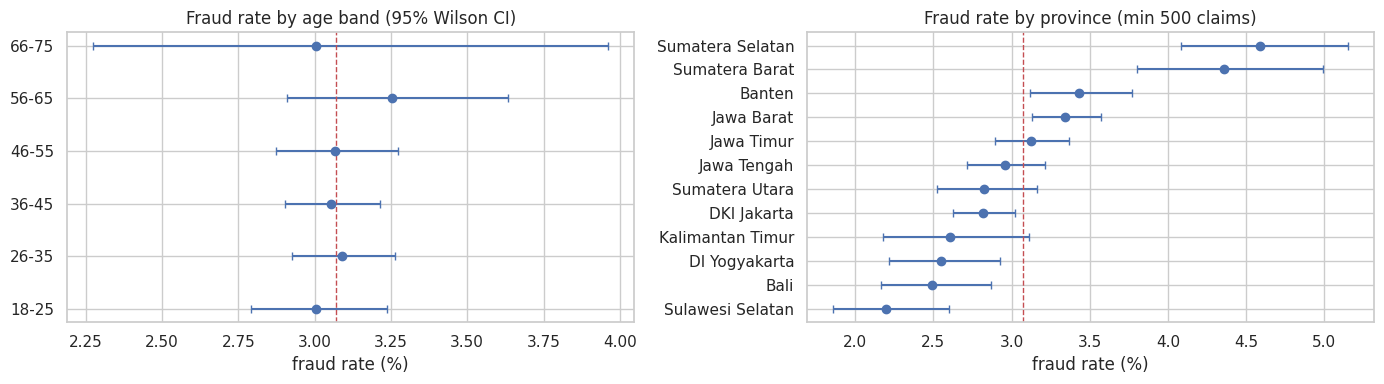

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].errorbar(
    age_table["fraud_rate_pct"],
    age_table["age_band"].astype(str),
    xerr=[age_table["fraud_rate_pct"] - age_table["ci_low_pct"], age_table["ci_high_pct"] - age_table["fraud_rate_pct"]],
    fmt="o",
    color="#4C72B0",
    capsize=3,
)
axes[0].axvline(BASE_RATE * 100, color="#C44E52", linestyle="--", linewidth=1)
axes[0].set_title("Fraud rate by age band (95% Wilson CI)")
axes[0].set_xlabel("fraud rate (%)")
axes[0].set_ylabel("")

province_plot = province_table.sort_values("fraud_rate_pct")
axes[1].errorbar(
    province_plot["fraud_rate_pct"],
    province_plot["province"],
    xerr=[province_plot["fraud_rate_pct"] - province_plot["ci_low_pct"], province_plot["ci_high_pct"] - province_plot["fraud_rate_pct"]],
    fmt="o",
    color="#4C72B0",
    capsize=3,
)
axes[1].axvline(BASE_RATE * 100, color="#C44E52", linestyle="--", linewidth=1)
axes[1].set_title("Fraud rate by province (min 500 claims)")
axes[1].set_xlabel("fraud rate (%)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

## 12. Split sanity check

The split is determined by `incident_date`: train 2021-2023, validation 2024 H1, test 2024 H2-2025. There must be no date overlap, and class distribution must be reported per split.

In [28]:
split_table = (
    features.groupby("split")
    .agg(
        claims=("claim_id", "size"),
        frauds=("is_fraud", "sum"),
        fraud_rate=("is_fraud", "mean"),
        first_date=("incident_date", "min"),
        last_date=("incident_date", "max"),
    )
    .assign(fraud_rate_pct=lambda frame: frame["fraud_rate"] * 100)
)
display(split_table)

print("Class share within each split (%)")
display(pd.crosstab(features["split"], features["is_fraud"], normalize="index").mul(100))

print("Sales channel mix within each split (%)")
display(pd.crosstab(features["split"], features["sales_channel_clean"], normalize="index").mul(100))

print("Boundary check")
for split in ["train", "validation", "test"]:
    subset = features[features["split"] == split]
    print(f"{split:10s} {subset['incident_date'].min().date()} -> {subset['incident_date'].max().date()} | rows {len(subset):,}")

,claims,frauds,fraud_rate,first_date,last_date,fraud_rate_pct
split,,,,,,
test,55116,1784,0.0324,2024-07-01,2025-12-31,3.2368
train,79329,2370,0.0299,2021-01-05,2023-12-31,2.9876
validation,15555,452,0.0291,2024-01-01,2024-06-30,2.9058


Class share within each split (%)


is_fraud,0,1
split,,
test,96.7632,3.2368
train,97.0124,2.9876
validation,97.0942,2.9058


Sales channel mix within each split (%)


sales_channel_clean,agent,broker,online
split,,,
test,43.1036,18.6679,38.2285
train,50.7028,21.3024,27.9948
validation,45.5609,19.9743,34.4648


Boundary check
train      2021-01-05 -> 2023-12-31 | rows 79,329
validation 2024-01-01 -> 2024-06-30 | rows 15,555
test       2024-07-01 -> 2025-12-31 | rows 55,116


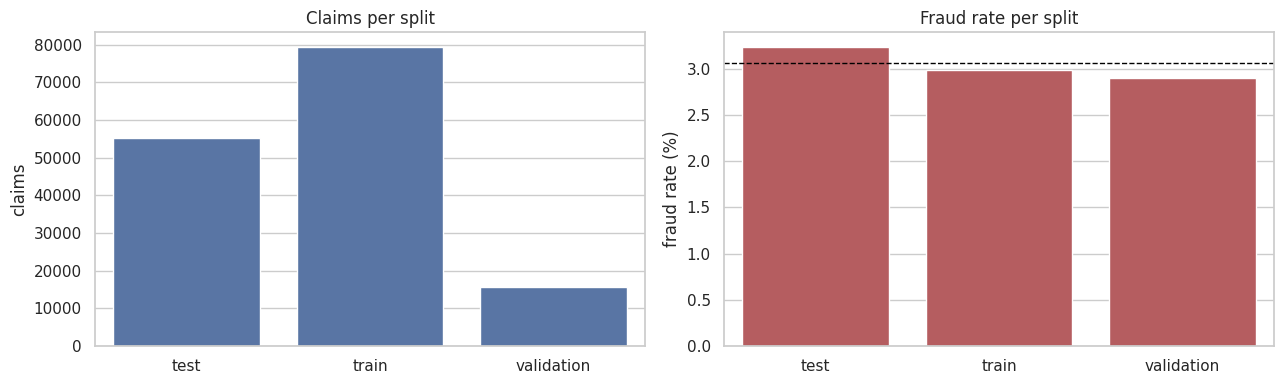

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.barplot(data=split_table.reset_index(), x="split", y="claims", color="#4C72B0", ax=axes[0])
axes[0].set_title("Claims per split")
axes[0].set_xlabel("")
axes[0].set_ylabel("claims")

sns.barplot(data=split_table.reset_index(), x="split", y="fraud_rate_pct", color="#C44E52", ax=axes[1])
axes[1].axhline(BASE_RATE * 100, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Fraud rate per split")
axes[1].set_xlabel("")
axes[1].set_ylabel("fraud rate (%)")

plt.tight_layout()
plt.show()

## 13. Non-leakage feature correlation

The heatmap uses Spearman because many features are skewed. Leakage columns are intentionally excluded. High correlation between derived features (for example `claim_amount` and claim ratios) is expected and must be handled during modeling.

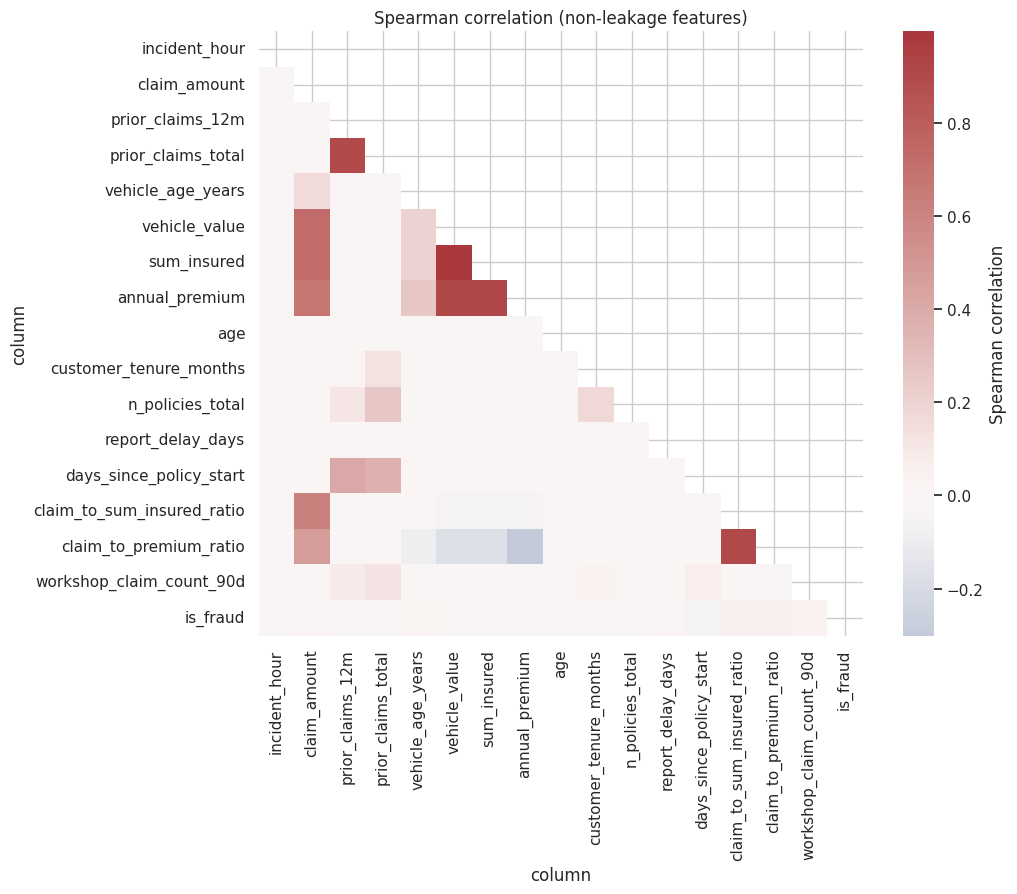

Correlation with is_fraud (sorted)


,spearman
column,
claim_to_sum_insured_ratio,0.0623
claim_to_premium_ratio,0.0542
workshop_claim_count_90d,0.0392
claim_amount,0.0335
report_delay_days,0.0239
vehicle_age_years,0.0189
age,0.0020
n_policies_total,-0.0024
annual_premium,-0.0068


In [30]:
numeric_columns = [
    "incident_hour",
    "claim_amount",
    "prior_claims_12m",
    "prior_claims_total",
    "vehicle_age_years",
    "vehicle_value",
    "sum_insured",
    "annual_premium",
    "age",
    "customer_tenure_months",
    "n_policies_total",
    "report_delay_days",
    "days_since_policy_start",
    "claim_to_sum_insured_ratio",
    "claim_to_premium_ratio",
    "workshop_claim_count_90d",
    "is_fraud",
]

correlation = features[numeric_columns].corr(method="spearman")
mask = np.triu(np.ones_like(correlation, dtype=bool))

plt.figure(figsize=(11, 9))
sns.heatmap(
    correlation,
    mask=mask,
    cmap="vlag",
    center=0,
    annot=False,
    square=True,
    cbar_kws={"label": "Spearman correlation"},
)
plt.title("Spearman correlation (non-leakage features)")
plt.tight_layout()
plt.show()

print("Correlation with is_fraud (sorted)")
display(correlation["is_fraud"].drop("is_fraud").sort_values(ascending=False).to_frame("spearman"))

## 14. Summary and checklist

Reference facts for the documented seed (`20261028`). Recompute them from your own run if you regenerate the data:

- **Volume:** 80,000 customers, 100,000 policies, 150,300 claim rows (150,000 unique), 304 workshops.
- **Target:** observed fraud 3.07%; latent 3.61%; 15% of fraud is undetected.
- **Leakage:** `claim_status`, `payout_amount`, `siu_investigation_flag`, and `days_to_settlement` separate the label almost perfectly. Drop them before modeling.
- **Workshops:** 10 legacy ring workshops + 4 new workshops (2025). Ring workshops have a much higher fraud rate than the base rate.
- **Drift:** 2025 changes ring composition and strengthens the online channel.
- **Missingness:** MNAR in three columns (higher for fraud).
- **Dirt:** 300 duplicates, 451 negative report delays, category capitalization variants, claim-amount outliers.
- **Split:** train 79,329 / validation 15,555 / test 55,116 rows.

Checklist before modeling:

1. Drop the four leakage columns and all truth columns.
2. De-duplicate `claim_id` before split/aggregation.
3. Normalize categories (strip + lower).
4. Handle negative report delays and claim-amount outliers explicitly.
5. Add missing indicators for MNAR columns.
6. Split by time; never split at random.
7. Choose the threshold from a cost matrix, not F1 alone.
8. Report PR-AUC, ROC-AUC, calibration, and a confusion matrix per split.
9. Decide whether to use `age` and `province`; document the rationale.
10. Always label **"synthetic data"** and seed `20261028` on every metric.

## 15. Limitations

- This is synthetic data. A model can only recover the planted rules, not real fraud behaviour.
- Claim frequency and exposure are not modelled; roughly 1.5 claims per policy is an assumption, not an actual calibration.
- Premium prices are not actuarial rates.
- There is no claim narrative, so text analysis is out of scope.
- `claims_truth.parquet` is for diagnostics and label-noise evaluation only; never join it into model features.